# 10 – The MIP segment (particle issue #1, Q3)

**Definitions** (issue #1). The **axis** is the straight line of the incoming direction (θ, φ) from the vertex (0, 0, 0); it enters
the calorimeter at the front face z = 3620.0 mm (ePIC `LFHCAL_zmin`). In front of the first tile there are 40.4 mm of steel (25.4 mm
mounting plate + 15 mm module front wall); every layer is 4 mm scintillator, 0.8 mm Kapton and 15.2 mm steel, so **a tile sits in front of
its absorber** and an interaction in the steel behind tile k is first seen in tile k + 1. Depths are measured from the entry point along the
axis. Every event is split into three regions: the **MIP segment** (energy within R = 5 cm of the axis in the tiles before the shower
start), the **core** (within 5 cm, from the shower start on) and the **halo** (farther than 5 cm): `E_vis = E_MIP + E_core + E_halo`.
A cell's energy is shared by the part of its 48.6 × 48.6 mm face inside R (8 × 8 points, "folding"); the cell-centre rule is kept for
comparison. Only prompt deposits (t < 100 ns) count, as in the report.

**Selection and statistics.** The entry point must be in the instrumented area and the axis must stay 10 cm inside it in all 60 layers
(no lateral leakage at the outer edge or the beam hole; 59 % of the events). Ratios of sums carry bootstrap errors, AUCs Hanley–McNeil
errors; efficiencies at 99 % electron rejection use thresholds from the train + val electrons applied to the test split.

**Simulation truth** (validation only). The CSV gives each cell's earliest contributor with its complete list of direct daughters. The
primary's cells are its prompt passage along the axis (99.9 % within 33 mm and within 0.06 ns of straight-line flight), so the deepest
primary tile marks the end of its track; daughters with hadronic products (n, π, d, α, ...) mark an inelastic interaction, no primary cell
at all an interaction in the front steel. About 13 % of crossed tiles miss the primary's cell (gaps, δ electrons arriving first).

In [1]:
import os, sys, json
if os.path.basename(os.getcwd()) == "notebooks":            # run from the repository root
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
import numpy as np, pandas as pd
from IPython.display import display
import core_mip as cm, core_mip_analysis as A, core_mip_figures as G
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
F = A.load_all()                                              # fiducial events with E_vis > 0
FINDER = json.load(open(os.path.join(cm.FEAT, "mip_finder.json")))
print({p: len(f) for p, f in F.items()}, "events;  finder:", FINDER["versions"]["strict"])

{'electron': 59475, 'muon': 59414, 'pion': 59333, 'proton': 59257} events;  finder: {'core_up': 2.0, 'halo_up': inf, 'cells_up': 2, 'n_consec': 2, 'core_sum': 6.0, 'core_sum_per_gev': 0.5}


## MIP calibration with muons

Per tile: the most probable value (MPV, 1 MIP) and the half widths at half maximum of the core energy times cos θ (path-length correction), muons with p ≥ 2 GeV/c; the first tile is calibrated on its own like every other tile. Right: the MPV in bins of θ, raw and corrected.

MPV tile 1: 0.6263 MeV, median of the tiles: 0.6178 MeV
core energy of muon tiles in MIP units, quantiles: {'0.5': 1.07, '0.9': 2.29, '0.95': 3.13, '0.98': 4.67, '0.99': 6.2, '0.995': 8.16}


,theta_lo,theta_hi,mpv_raw_MeV,mpv_cos_MeV,tiles
0,0.0526,0.2416,0.6310,0.6207,673197
1,0.2416,0.3311,0.6485,0.6215,673222
2,0.3311,0.4010,0.6681,0.6233,673196
3,0.4010,0.4612,0.6883,0.6250,673215
4,0.4612,0.5167,0.7100,0.6267,673187
5,0.5167,0.6283,0.7433,0.6312,673240


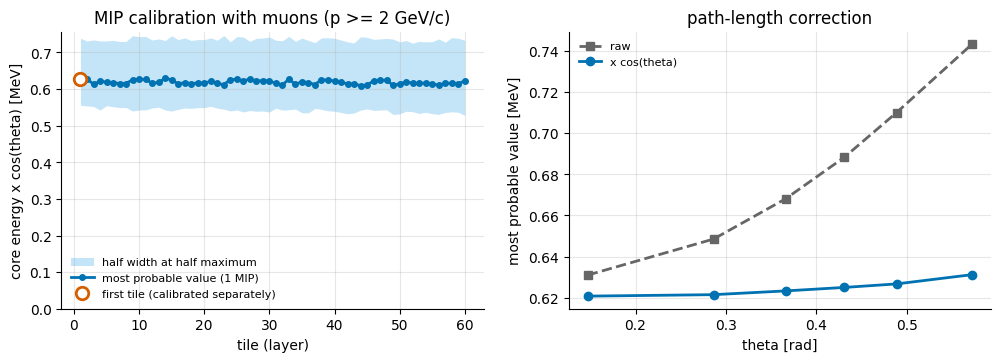

In [2]:
CAL = json.load(open(os.path.join(cm.FEAT, "mip_calibration.json")))
TH = A.calibration_theta_check()
G.q3_calibration(CAL, TH)
print(f"MPV tile 1: {CAL['mpv'][0]*1e3:.4f} MeV, median of the tiles: {np.median(CAL['mpv'])*1e3:.4f} MeV")
print("core energy of muon tiles in MIP units, quantiles:", {k: round(v, 2) for k, v in CAL["core_quantiles_mip"].items()})
display(TH.round(4))

## The MIP-segment finder

A tile is **MIP-like** if its core energy is at most `core_up` MIP, its energy outside R at most `halo_up` MIP and at most `cells_up` cells fire (> 0.3 MIP). The shower starts at the first `n_consec` consecutive non-MIP tiles whose summed core energy exceeds `core_sum + core_sum_per_gev · p` MIP (p is known from the tracker); empty tiles do not interrupt the segment. `L_MIP` is the depth of the last tile with a deposit on the axis before the start. The parameters were chosen on the train split against the simulation truth (`scripts/core_mip_tune.py`): among the settings with at most 3 % muon false starts per interaction length (the CALICE Si-W ECAL level), those within 0.01 of the best ±1-tile agreement with the true interaction (π and p, 3–5, 5–10, 10–20 GeV/c), then the best L_MIP efficiency at 99 % electron rejection. Gábor's original rule (core within the MIP band, outside-R energy below a threshold, ≤ 2 cells, two consecutive non-MIP tiles) and the narrow-deposit version are evaluated with the same metrics.

In [3]:
TM = FINDER["train_metrics"]
k = ["core_up", "halo_up", "cells_up", "n_consec", "core_sum", "core_sum_per_gev"]
show = ["had_pm1_3_20", "pion_early", "pion_late", "pion_missed", "muon_false_per_lambda", "eff99_pion_1_3", "eff99_pion_3_20", "eff99_proton_1_3", "eff99_proton_3_20"]
rows = {"chosen": TM["strict"], "issue rule (2.5 MIP band, no energy condition)": TM["gabor_rule"], "narrow deposit": TM["narrow"]}
display(pd.DataFrame({n: {a: r[a] for a in k + show} for n, r in rows.items()}).T.round(3))

,core_up,halo_up,cells_up,n_consec,core_sum,core_sum_per_gev,had_pm1_3_20,pion_early,pion_late,pion_missed,muon_false_per_lambda,eff99_pion_1_3,eff99_pion_3_20,eff99_proton_1_3,eff99_proton_3_20
chosen,2.0,inf,2.0,2.0,6.0,0.5,0.767,0.029,0.108,0.064,0.028,0.713,0.725,0.726,0.713
"issue rule (2.5 MIP band, no energy condition)",2.5,1.168,2.0,2.0,0.0,0.0,0.656,0.250,0.087,0.016,0.099,0.589,0.648,0.632,0.614
narrow deposit,inf,1.168,2.0,2.0,0.0,0.0,0.597,0.178,0.186,0.027,0.009,0.127,0.391,0.084,0.331


## L_MIP distributions and P(L_MIP ≥ 8 / 10 cm)

Dashed: the same probability for the true passage of the primary (depth of its last tile before the interaction).

,particle,p_range,events,P_L_gt_0,P_L_ge_8,P_L_ge_10,truth_reaches_tile1
0,electron,1-2,3012,0.108,0.027,0.015,NaN
1,electron,2-3,2986,0.050,0.008,0.002,NaN
2,electron,3-5,5933,0.035,0.005,0.002,NaN
3,electron,5-10,14796,0.024,0.003,0.001,NaN
4,electron,10-20,29768,0.017,0.001,0.001,NaN
5,muon,1-2,2922,0.997,0.990,0.988,NaN
6,muon,2-3,2964,0.994,0.985,0.982,NaN
7,muon,3-5,6005,0.994,0.985,0.981,NaN
8,muon,5-10,14895,0.994,0.988,0.984,NaN
9,muon,10-20,29772,0.997,0.993,0.990,NaN


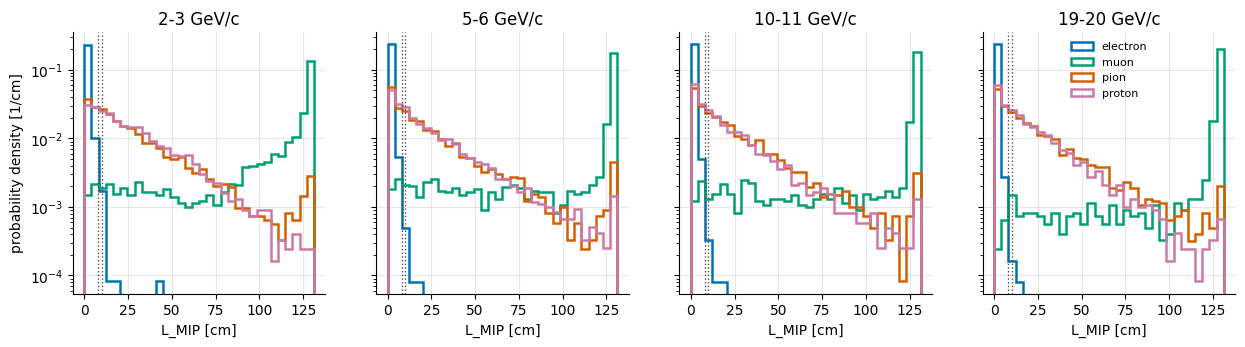

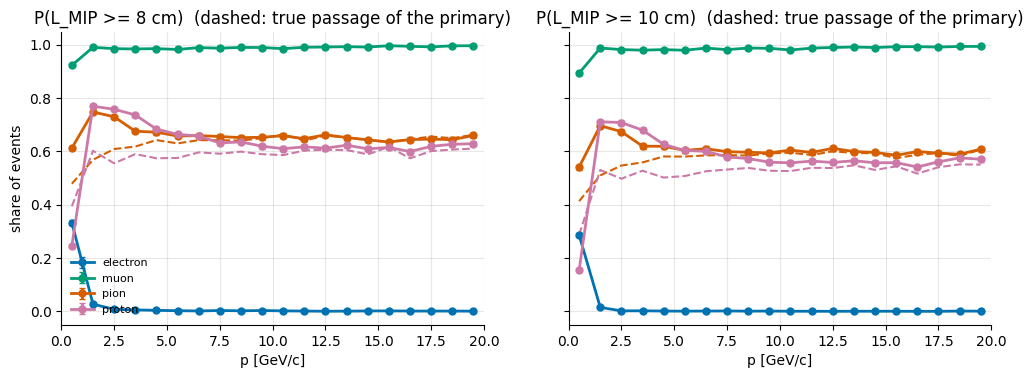

In [4]:
G.q3_lmip(F)
PL = A.p_long(F)
G.q3_plong(PL)
CL = A.claims(F)
display(CL["claim1_may_or_may_not_be_there"].round(3))

## Effective interaction length

Truncated, censored exponential likelihood on 8–80 cm (p ≥ 3 GeV/c; the interaction is placed in the steel in front of the start tile; events without a start are censored). `truth` uses the primary's last tile; the finder values measure the depth of the first *visible* shower start; `corrected` removes the muon false-start rate. The PDG values of the layer stack are for 200 GeV/c.

,particle,p_range,truth [cm],strict [cm],narrow [cm],strict corrected [cm],PDG stack [cm]
0,pion,3-20,24.4 ± 0.1,27.9 ± 0.2,26.6 ± 0.2,29.1,26.0
1,pion,3-5,22.7 ± 0.4,31.0 ± 0.5,25.8 ± 0.4,32.4,26.0
2,pion,5-10,23.9 ± 0.2,27.7 ± 0.3,26.8 ± 0.3,28.8,26.0
3,pion,10-20,25.0 ± 0.2,27.4 ± 0.2,26.7 ± 0.2,28.6,26.0
4,proton,3-20,19.9 ± 0.1,25.7 ± 0.1,22.4 ± 0.1,26.7,21.2
5,proton,3-5,19.1 ± 0.3,35.5 ± 0.6,23.6 ± 0.4,37.4,21.2
6,proton,5-10,19.5 ± 0.2,26.1 ± 0.3,22.4 ± 0.2,27.1,21.2
7,proton,10-20,20.2 ± 0.2,23.9 ± 0.2,22.1 ± 0.2,24.7,21.2


muon false starts: {'strict': {'lambda_fake_cm': 697.4332111769824, 'se': np.float64(9.66329962176896), 'starts': 5209, 'share_with_start': 0.15769259452606457}, 'narrow': {'lambda_fake_cm': 3649.3599661961402, 'se': np.float64(112.72910582654922), 'starts': 1048, 'share_with_start': 0.0554478335446342}}


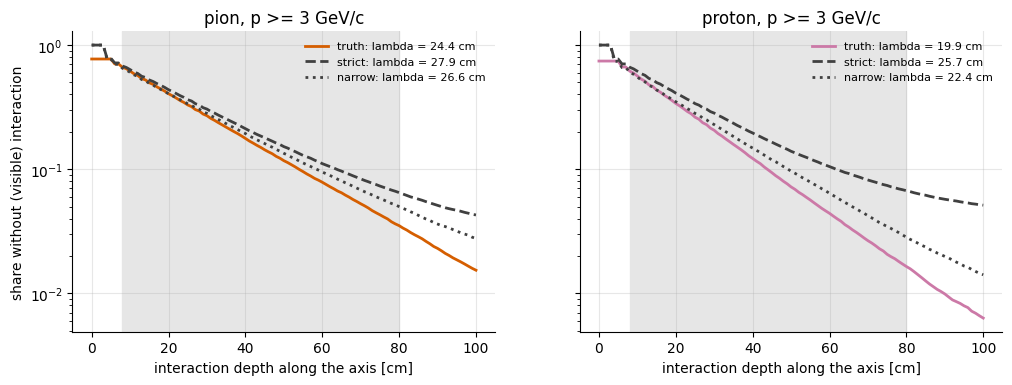

In [5]:
LAM = A.q3_lambda(F)
G.q3_survival(F, LAM, A.interaction_depth)
rows = []
for p in A.HADRONS:
    for rng, r in LAM[p].items():
        if isinstance(r, dict):
            rows.append({"particle": p, "p_range": rng, **{f"{v} [cm]": f"{x['lambda_cm']:.1f} ± {x['se']:.1f}" for v, x in r.items()},
                         "strict corrected [cm]": f"{r['strict']['lambda_corrected_cm']:.1f}", "PDG stack [cm]": LAM[p]["pdg_stack_cm"]})
display(pd.DataFrame(rows))
print("muon false starts:", LAM["muon_false_start"])

## The start tile against the true interaction

`exact`: start in the tile right after the interaction or in the tile in front of it (backsplash); `within_1`: one more tile on either side; `early` / `late`: farther away; `no_start`: no shower start found. The second table shows why low momenta are hard: the core energy in the two tiles after the true interaction, compared with the start threshold.

,particle,p_range,events,exact,within_1,early,late,no_start
0,pion,1-2,2975,0.317,0.408,0.021,0.063,0.509
1,pion,2-3,2998,0.443,0.575,0.047,0.117,0.261
2,pion,3-5,5970,0.573,0.715,0.058,0.120,0.107
3,pion,5-10,14836,0.697,0.819,0.036,0.118,0.027
4,pion,10-20,29543,0.758,0.867,0.019,0.103,0.011
5,proton,1-2,2740,0.235,0.276,0.008,0.061,0.655
6,proton,2-3,3009,0.352,0.426,0.005,0.106,0.464
7,proton,3-5,5940,0.487,0.599,0.012,0.171,0.218
8,proton,5-10,14683,0.627,0.758,0.013,0.188,0.042
9,proton,10-20,29546,0.698,0.833,0.010,0.150,0.007


,particle,p_range,events,median_core_mip_two_tiles,share_below_threshold
0,pion,1-2,2126,5.786,0.558
1,pion,2-3,2208,9.475,0.398
2,pion,3-5,4532,14.769,0.260
3,pion,5-10,11386,26.564,0.175
4,pion,10-20,22882,40.028,0.151
0,proton,1-2,1955,4.194,0.674
1,proton,2-3,2150,6.740,0.526
2,proton,3-5,4317,10.599,0.394
3,proton,5-10,10864,20.964,0.260
4,proton,10-20,22081,36.685,0.195


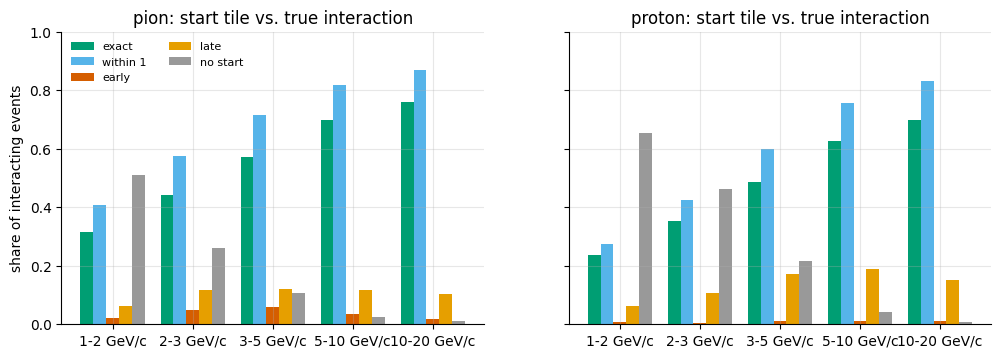

In [6]:
AGR = A.q3_truth_agreement(F)
G.q3_truth(AGR)
display(AGR.round(3))
display(pd.concat([A.start_visibility(p) for p in A.HADRONS]).round(3))

## Hadron identification

Test split: AUC and hadron efficiency at 99 % electron rejection for `f_core`, `L_MIP`, the readout-segment variable `seg1` (energy of tiles 1–5, which the ePIC LFHCal reads out as one channel) and the combination (logistic regression on `f_core` and `L_MIP`, trained on the train split). `eff99_truth_bound` applies the electron threshold of L_MIP to the true passage length of the hadrons.

feature,L_MIP,combined,f_core,seg1
electron_vs_pion,,,,
1,0.613,0.861,0.856,0.562
2,0.741,0.984,0.995,0.678
4,0.751,0.986,0.986,0.692
9,0.766,0.991,0.989,0.708
14,0.733,0.984,0.982,0.719
19,0.765,0.979,0.979,0.750


feature,L_MIP,combined,f_core,seg1
electron_vs_proton,,,,
1,0.653,0.862,0.855,0.693
2,0.802,0.978,0.978,0.806
4,0.765,0.998,0.998,0.721
9,0.719,1.000,1.000,0.677
14,0.706,1.000,1.000,0.706
19,0.739,1.000,1.000,0.757


feature,L_MIP,combined,f_core,seg1
pion vs proton AUC,,,,
0,0.276,0.774,0.344,0.425
1,0.480,0.532,0.549,0.532
2,0.532,0.602,0.593,0.568
4,0.519,0.590,0.589,0.520
9,0.459,0.618,0.607,0.460
19,0.467,0.656,0.653,0.472


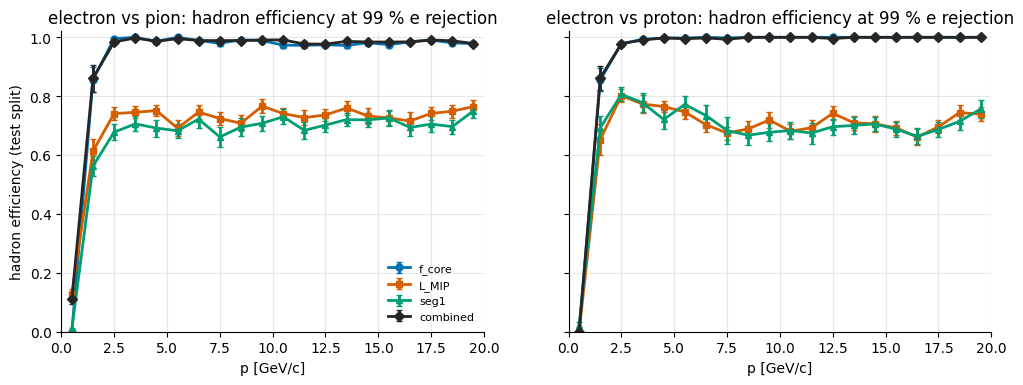

In [7]:
CLS = A.q3_classify(F)
G.q3_eff99(CLS)
for pair in ("electron_vs_pion", "electron_vs_proton"):
    display(CLS[CLS.pair == pair].pivot_table(index="bin", columns="feature", values="eff99").loc[[1, 2, 4, 9, 14, 19]].round(3).rename_axis(pair))
display(CLS[CLS.pair == "pion_vs_proton"].pivot_table(index="bin", columns="feature", values="auc").loc[[0, 1, 2, 4, 9, 19]].round(3).rename_axis("pion vs proton AUC"))

## Gábor's four properties of the MIP segment

1. *it may or may not be there* – shares above, and the truth share of primaries that reach tile 1;
2. *if it is there, it always starts at the entry point* – MIP-like runs of ≥ 4 tiles that begin after the shower start, and who carries them (truth);
3. *very small energy deposit, along the axis only* – energy in the tiles the primary crossed before its interaction (truth);
4. *8–10 cm or longer is a very powerful hadron indicator* – probabilities for electrons and hadrons and the likelihood ratio.

In [8]:
display(CL["claim2_starts_at_entry"].round(3))
display(pd.DataFrame({p: A.claim3_pre_interaction(p) for p in A.HADRONS}).round(3))
display(CL["claim4_indicator"].round(3))

,particle,p_range,events,late_run_ge_4_tiles,late_run_by_primary,late_run_by_secondary
0,pion,1-2,2986,0.042,0.005,0.036
1,pion,2-3,3006,0.098,0.009,0.089
2,pion,3-5,5988,0.141,0.012,0.129
3,pion,5-10,14880,0.113,0.008,0.105
4,pion,10-20,29641,0.092,0.005,0.087
5,proton,1-2,3023,0.010,0.001,0.009
6,proton,2-3,3012,0.053,0.000,0.053
7,proton,3-5,5944,0.112,0.001,0.111
8,proton,5-10,14691,0.126,0.001,0.125
9,proton,10-20,29570,0.095,0.000,0.094


,pion,proton
tiles,397507.000,311411.000
events,32440.000,29839.000
core_mip_per_tile,1.449,1.356
primary_core_mip_per_tile,1.136,1.134
secondary_core_mip_per_tile,0.313,0.222
outside_R_mip_per_tile,0.604,0.775
share_tiles_with_outside_R_gt_1mip,0.132,0.166
share_tiles_non_mip,0.196,0.181
share_tiles_fail_core,0.158,0.129
share_tiles_fail_halo,0.000,0.000


,hadron,p_range,L_min_cm,P_electron,P_hadron,likelihood_ratio,purity_equal_mix
0,pion,1-2,8,0.027,0.748,27.469,0.965
1,pion,1-2,10,0.015,0.697,45.611,0.979
2,proton,1-2,8,0.027,0.769,28.263,0.966
3,proton,1-2,10,0.015,0.711,46.569,0.979
4,pion,2-3,8,0.008,0.730,90.808,0.989
5,pion,2-3,10,0.002,0.674,335.420,0.997
6,proton,2-3,8,0.008,0.758,94.304,0.990
7,proton,2-3,10,0.002,0.708,352.431,0.997
8,pion,3-5,8,0.005,0.674,137.860,0.993
9,pion,3-5,10,0.002,0.619,334.085,0.997
